# Examen — Módulo 1: Preparación de datos
**Aprendizaje Supervisado · Evaluación de las sesiones 1–3** (EDA, preprocesamiento, ingeniería y selección de variables)

**Instrucciones**

- Trabajo **individual**. Duración sugerida: **120 minutos**. Material permitido: tus notas, la presentación y la documentación oficial de pandas, scikit-learn y matplotlib.
- Escribe tu nombre en la primera celda de código (`NOMBRE`).
- Sustituye cada `...` (marcado con ✏️) por tu código. En las preguntas con **“Respuesta:”**, escribe tu explicación en la celda de texto que sigue (editando la celda de Markdown).
- Antes de entregar, ejecuta **Kernel → Reiniciar y ejecutar todo**; el notebook debe correr de principio a fin sin errores.
- Los datos son simulados y se generan con semilla fija: tus resultados deben ser reproducibles.
- Se evalúa tanto el **código** como la **calidad de la justificación**. Las respuestas escritas deben ser breves y precisas.

| Parte | Tema | Puntos |
|---|---|---|
| I | Análisis exploratorio de datos | 30 |
| II | Preprocesamiento de datos | 35 |
| III | Ingeniería y selección de variables | 35 |
| | **Total** | **100** |


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder,
                                   OrdinalEncoder, PolynomialFeatures)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, f_classif, mutual_info_classif,
                                       RFE, RFECV, SelectFromModel)
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

NOMBRE = "Angel Ismael Basto González"  # ✏️ escribe tu nombre completo


In [5]:
# ---------------------------------------------------------------------------------------------
# Generadores de datos (NO los modifiques; no necesitas leerlos para resolver el examen)
# ---------------------------------------------------------------------------------------------
def genera_viviendas(n=1200, seed=2026):
    """Viviendas en venta en una ciudad (datos simulados). Precio en miles de pesos."""
    r = np.random.default_rng(seed)
    zona = r.choice(["Norte", "Centro", "Poniente", "Oriente", "Sur", "Costa"], n, p=[.30, .15, .22, .14, .17, .02])
    acab = r.choice(["Básico", "Medio", "Alto", "Premium"], n, p=[.30, .40, .22, .08])
    sup = np.exp(r.normal(np.log(110), .38, n)).round(0)
    rec = np.clip(np.round(sup / 45 + r.normal(0, .6, n)), 1, 6).astype(int)
    ant = np.clip(r.gamma(1.6, 9, n), 0, 70).round(0)
    dist = np.round(r.gamma(2.2, 3.2, n), 1)
    zef = pd.Series(zona).map(
        {"Norte": .25, "Centro": .05, "Poniente": .10, "Oriente": -.20, "Sur": -.30, "Costa": .55}).values
    aef = pd.Series(acab).map({"Básico": 0, "Medio": .18, "Alto": .40, "Premium": .75}).values
    lp = 1.2 + .85 * np.log(sup) + zef + aef - .008 * ant - .035 * dist + .04 * rec + r.normal(0, .17, n)
    precio = (np.exp(lp) * 25).round(0)
    idx = r.choice(n, 10, replace=False)
    precio[idx] *= r.uniform(3.5, 6, 10)
    df = pd.DataFrame(dict(zona=zona, acabados=acab, superficie_m2=sup, recamaras=rec,
                           antiguedad_anios=ant, dist_centro_km=dist, precio_miles=precio.round(0)))
    pm = np.where(np.isin(zona, ["Sur", "Oriente"]), .22, .04)
    df.loc[r.random(n) < pm, "antiguedad_anios"] = np.nan
    df.loc[r.random(n) < .04, "superficie_m2"] = np.nan
    return df


def genera_biomarcadores(n=400, seed=7):
    """400 pacientes, 26 mediciones de laboratorio y un diagnóstico y ∈ {0, 1} (datos simulados)."""
    r = np.random.default_rng(seed)
    y = r.integers(0, 2, n)
    s = 2 * y - 1
    a = r.normal(0.9 * s, 1.0)
    b = 100 + 15 * r.normal(0.6 * s, 1.0)
    c = 0.02 * r.normal(0.8 * s, 1.0)
    cuad = np.where(y == 1, r.choice([-1, 1], n) * r.normal(1.6, .35, n), r.normal(0, .45, n))
    a_copia = a + r.normal(0, .15, n)
    casi = 5 + 1e-3 * r.normal(0, 1, n)
    ruido = r.normal(0, 1, (n, 20)) * r.choice([1, 1, 1, 10, 50], 20)
    cols = {"lin_a": a, "lin_b": b, "lin_c": c, "cuad": cuad, "lin_a_copia": a_copia, "casi_const": casi}
    for i in range(20):
        cols[f"ruido_{i + 1:02d}"] = ruido[:, i]
    return pd.DataFrame(cols), pd.Series(y, name="y")


---
## Parte I — Análisis exploratorio de datos (30 puntos)

Trabajarás con `viv`: **1 200 viviendas en venta** de una ciudad (datos simulados).
Variables: `zona` y `acabados` (categóricas; `acabados` es ordinal: Básico < Medio < Alto < Premium), `superficie_m2`, `recamaras`,
`antiguedad_anios`, `dist_centro_km` y el objetivo `precio_miles` (miles de pesos). Hay valores faltantes.

In [6]:
viv = genera_viviendas()
NUM = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km", "precio_miles"]
print(viv.shape)
viv.head()

(1200, 7)


,zona,acabados,superficie_m2,recamaras,antiguedad_anios,dist_centro_km,precio_miles
0,Norte,Medio,74.0,2,25.0,8.1,4289.0
1,Poniente,Medio,166.0,4,14.0,9.4,7465.0
2,Poniente,Premium,211.0,4,7.0,2.1,16996.0
3,Centro,Medio,153.0,4,30.0,3.4,6301.0
4,Centro,Básico,101.0,2,0.0,9.5,4444.0


### Pregunta I.1 · Asimetría y curtosis  *(4 pts)*

Calcula la **asimetría** y la **curtosis (excedente)** de las cinco variables numéricas `NUM` y guarda en `mas_asimetrica` el *nombre* de la variable con mayor asimetría.

In [26]:
asim = viv[NUM].skew()  # ✏️ Series con la asimetría de cada variable de NUM
curt = viv[NUM].kurt()  # ✏️ Series con la curtosis excedente de cada variable de NUM
mas_asimetrica = asim.abs().idxmax()  # ✏️ nombre (str) de la variable más asimétrica

print(pd.DataFrame({"asimetría": asim, "curtosis": curt}).round(2))
print("Más asimétrica:", mas_asimetrica)

                  asimetría  curtosis
superficie_m2          1.00      1.42
recamaras              0.57      0.10
antiguedad_anios       1.41      2.36
dist_centro_km         1.16      1.87
precio_miles           3.38     22.95
Más asimétrica: precio_miles


### Pregunta I.2 · Interpretar la forma de `precio_miles`  *(3 pts)*

Observa la media y la mediana del precio y su histograma. En **3 a 5 líneas**: ¿qué forma tiene la distribución según la asimetría y la curtosis? ¿Qué medida de centro describiría mejor un precio “típico” y por qué?

media = 5,271   mediana = 4,504


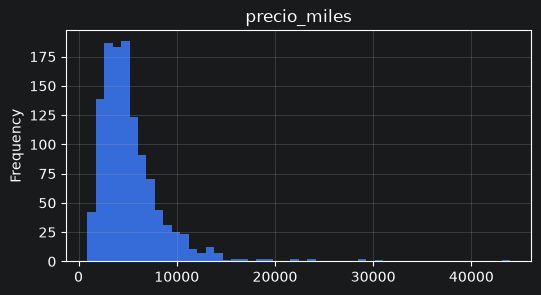

In [24]:
print(f"media = {viv.precio_miles.mean():,.0f}   mediana = {viv.precio_miles.median():,.0f}")
viv.precio_miles.plot.hist(bins=50, figsize=(6, 3), title="precio_miles");

**Respuesta:**
> precio_miles tiene una asimetría de 3.38, por lo que es asimétrica positiva (tiene una cola larga hacia la derecha). La medida que describiría mejor un precio típico sería la mediana, ya que con una curtosis de 22.95 podemos saber que tiene colas pesadas que arrastran la media (media de 5,271 contra mediana de 4,504). La mediana es más robusta a los outliers y es por eso que nos proporciona una medida de centro más adecuada para esta variable.


### Pregunta I.3 · Regla del IQR  *(5 pts)*

Escribe la función `atipicos_iqr(s, k=1.5)` que, dada una Series `s`, devuelva una Series booleana que marque como atípicos los valores fuera de $[Q_1 - k\,\mathrm{IQR},\; Q_3 + k\,\mathrm{IQR}]$ (ignora los `NaN`). Después cuenta los atípicos de cada variable de `NUM`.

In [38]:
def atipicos_iqr(s, k=1.5):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])  # ✏️ calcula Q1, Q3, IQR y devuelve la máscara booleana
    iqr = q3 - q1

    lim_inf, lim_sup = q1 - k * iqr, q3 + k * iqr
    return (s < lim_inf) | (s > lim_sup)


n_atip = {col: int(atipicos_iqr(viv[col]).sum()) for col in
          NUM}  # ✏️ dict {variable: número de atípicos} para cada variable de NUM
print(n_atip)

{'superficie_m2': 20, 'recamaras': 78, 'antiguedad_anios': 37, 'dist_centro_km': 25, 'precio_miles': 57}


### Pregunta I.4 · El logaritmo y los atípicos  *(4 pts)*

Crea `log_precio = np.log(viv.precio_miles)`, calcula su asimetría y cuántos atípicos marca la regla del IQR. Luego responde en **3 a 4 líneas**: ¿la transformación resolvió el problema de los atípicos? Entre eliminarlos, dejarlos o transformarlos, ¿qué harías con las viviendas más caras y por qué? (Recuerda cómo se generó el dato: hay viviendas con precios muy superiores al de su tipo.)

In [46]:
log_precio = np.log(viv.precio_miles)  # ✏️
asim_log = log_precio.skew()  # ✏️ asimetría de log_precio
n_atip_log = int(atipicos_iqr(log_precio).sum())  # ✏️ número de atípicos de log_precio según la regla del IQR
print(f"asimetría: {asim_log:.2f}   atípicos: {n_atip_log}")

asimetría: 0.22   atípicos: 14


**Respuesta:**

> La transformación redujo la asimetría, de 3.38 a 0.22, y el número de atípicos de 57 a 14, es decir, no resolvió el problema completamente, aún tenemos casos atípicos. En este caso valdría la pena eliminar las viviendas cuyo precio es atípico porque al tener un precio que no corresponde al tipo de casa parece un error de captura o un caso que el modelo no puede aprender y ocasionaría errores en las predicciones.



### Pregunta I.5 · Pearson, Spearman y transformaciones  *(6 pts)*

Calcula, entre el precio y `superficie_m2`, cuatro coeficientes y guárdalos en el dict `r`:
`"pearson_crudo"` (precio sin transformar), `"pearson_log"` (con `log_precio`), `"spearman_crudo"` y `"spearman_log"`.
Después explica en **3 a 4 líneas**: (a) por qué `spearman_crudo` y `spearman_log` coinciden, y (b) por qué `pearson_crudo` y `pearson_log` no.

In [47]:
d = pd.DataFrame({"precio": viv.precio_miles, "log_precio": log_precio, "superficie": viv.superficie_m2})

r = {
    "pearson_crudo": d["precio"].corr(d["superficie"]),  # ✏️
    "pearson_log": d["log_precio"].corr(d["superficie"]),  # ✏️
    "spearman_crudo": d["precio"].corr(d["superficie"], method="spearman"),  # ✏️
    "spearman_log": d["log_precio"].corr(d["superficie"], method="spearman"),  # ✏️
}
print({k: round(v, 3) for k, v in r.items()})

{'pearson_crudo': np.float64(0.546), 'pearson_log': np.float64(0.616), 'spearman_crudo': np.float64(0.637), 'spearman_log': np.float64(0.637)}


**Respuesta:**

> a) Spearman ordena los datos de menor a mayor y conserva solamente el orden. Es decir, le importa si la casa A cuesta más que la casa B pero no le importa cuánto más. Al aplicar log el orden no cambia entonces los rangos son idénticos y el coeficiente también.

> b) Pearson mide qué tan bien los puntos se ajustan a una línea recta y utiliza los valores reales, no los rangos. Al aplicar log se reducen los valores, pero en proporciones diferentes, comprime mucho más los valores grandes que los pequeños haciendo que los atípicos pierdan peso y que la relación se vuelva más lineal, es por eso que Pearson subió de 0.546 a 0.616.


### Pregunta I.6 · Verdadero o falso  *(4 pts)*

Marca cada afirmación como `True` (verdadera) o `False` (falsa). Cada acierto vale 1 punto; no hay penalización por error.

- **a)** Si el coeficiente de correlación de Pearson entre $X$ e $Y$ es 0, entonces $X$ e $Y$ son independientes.
- **b)** La mediana es más robusta que la media frente a valores atípicos.
- **c)** Una correlación de 0.9 entre las ventas de helado y los ahogamientos demuestra que el helado causa ahogamientos.
- **d)** Una curtosis excedente positiva indica colas más pesadas que las de una distribución normal.

In [48]:
resp_VF = {"a": False, "b": True, "c": False, "d": True}  # ✏️ reemplaza None por True o False

### Pregunta I.7 · Matriz de correlación y multicolinealidad  *(4 pts)*

Calcula la matriz de correlación de Pearson de `superficie_m2`, `recamaras`, `antiguedad_anios`, `dist_centro_km` y `log_precio`, dibújala como mapa de calor (con barra de color y etiquetas) y guarda en `par` la tupla con los nombres de las **dos variables explicativas** (sin contar `log_precio`) más correlacionadas entre sí en valor absoluto. En **2 a 3 líneas**: ¿por qué sería un problema meter ambas en una regresión lineal y qué harías?

('recamaras', 'superficie_m2')


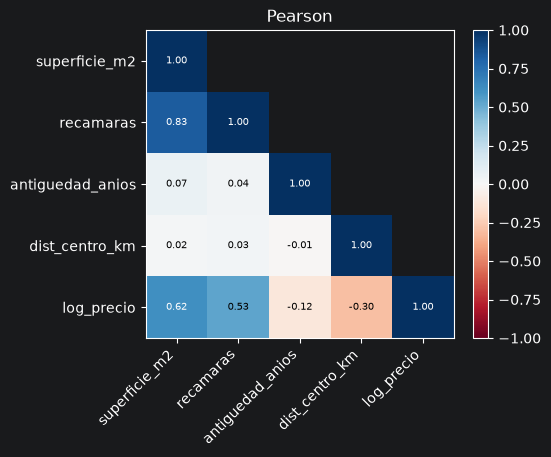

In [61]:
def heatmap(Cm, ax, titulo):
    mask = np.triu(np.ones(Cm.shape, dtype=bool), k=1)  # oculta el triángulo superior (es repetido)
    im = ax.imshow(np.ma.array(Cm.values, mask=mask), cmap="RdBu", vmin=-1, vmax=1)
    n = len(Cm)
    ax.set_xticks(range(n));
    ax.set_xticklabels(Cm.columns, rotation=45, ha="right")
    ax.set_yticks(range(n));
    ax.set_yticklabels(Cm.index)
    ax.grid(False)
    for i in range(n):
        for j in range(i + 1):
            v = Cm.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
    ax.set_title(titulo)
    return im


cols = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km"]
C = viv[cols].assign(
    log_precio=log_precio).corr()  # ✏️ matriz de correlación de cols + log_precio (use viv y log_precio)

fig, ax = plt.subplots(figsize=(5, 4))
im = heatmap(C, ax, "Pearson")  # ✏️ mapa de calor de C con barra de color y etiquetas de ejes

fig.colorbar(im, ax=ax)

Cx = C.loc[cols, cols]
tri = np.tril(np.ones(Cx.shape, dtype=bool), k=-1)
par = Cx.where(tri).stack().abs().idxmax()  # ✏️ tupla (var1, var2) de las dos explicativas más correlacionadas
print(par)

**Respuesta:**

> Meter ambas en una regresión lineal causaría multicolinealidad, el modelo no puede separar el efecto de cada una, por lo que sus coeficientes se vuelven inestables y difíciles de interpretar. Lo que haría es eliminar la variable que tiene menor correlación con el objetivo, en este caso, recamaras con 0.53 tiene menor correlación con log_precio que superficie_m2 con 0.62.


---
## Parte II — Preprocesamiento de datos (35 puntos)

Seguimos con el conjunto `viv`. Ahora el objetivo es **predecir `log(precio_miles)`** con un modelo lineal, cuidando el preprocesamiento.

### Pregunta II.1 · Cuantificar los valores faltantes  *(4 pts)*

Calcula (a) el número y el porcentaje de valores faltantes por columna y (b) la **proporción de faltantes por `zona`** para `antiguedad_anios` y `superficie_m2`.

In [71]:
faltantes = pd.DataFrame({"n": viv.isna().sum(),
                          "%": viv.isna().mean()})  # ✏️ DataFrame con columnas "n" y "%" (una fila por columna de viv)
falt_por_zona = falt_por_zona = viv[["antiguedad_anios", "superficie_m2"]].isna().groupby(
    viv["zona"]).mean()  # ✏️ DataFrame: filas = zona, columnas = proporción de NaN en antiguedad_anios y superficie_m2
print(faltantes[faltantes["n"] > 0])
print((100 * falt_por_zona).round(1))

                    n         %
superficie_m2      62  0.051667
antiguedad_anios  107  0.089167
          antiguedad_anios  superficie_m2
zona                                     
Centro                 2.2            6.7
Costa                  0.0            4.0
Norte                  3.0            4.0
Oriente               19.1            4.4
Poniente               4.4            5.2
Sur                   21.6            6.6


### Pregunta II.2 · Mecanismo de los faltantes  *(3 pts)*

Con lo que observaste en II.1, ¿qué mecanismo (MCAR, MAR o MNAR) es más plausible para `antiguedad_anios` y cuál para `superficie_m2`? Justifica con los números. ¿Qué riesgo habría al **borrar** las filas incompletas?

**Respuesta:**

> Para antiguedad_anios el mecanismo parece MAR ya que en la mayoría de las zonas el porcentaje de faltantes es similar (entre 0 y 4.4) pero Oriente y Sur se elevan muchísimo (19.1 y 21.6), por lo que parece que los faltantes se relacionan con la zona, y para superficie_m2 parece más MCAR ya que el porcentaje de faltantes es similar en todas las zonas y se mantiene un porcentaje bajo de entre 4 y 6.7 de faltantes. Borrar las filas incompletas nos haría perder 163 filas (13.6%) y no sería equitativo, Sur y Oriente perderían más filas que el resto sesgando la muestra hacia zonas más caras, y dificultando predecir el precio para esas zonas.



### Pregunta II.3 · División entrenamiento / prueba  *(5 pts)*

Define `X = viv` sin `precio_miles` e `y = log_precio`. Separa 80 % para entrenamiento y 20 % para prueba (`random_state=0`) **estratificando por `zona`**, y muestra la proporción de cada zona en `X_train` y `X_test`. En **2 líneas**: ¿por qué conviene estratificar en este conjunto?

In [75]:
X = viv.drop(columns="precio_miles")  # ✏️
y = log_precio
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0,
                                                    stratify=X["zona"])  # ✏️ train_test_split estratificado por zona

prop = pd.DataFrame({"train": X_train["zona"].value_counts(normalize=True), "test": X_test["zona"].value_counts(
    normalize=True)})  # ✏️ DataFrame: proporción de cada zona en train y en test
print((100 * prop).round(1))

          train  test
zona                 
Norte      27.4  27.5
Poniente   22.5  22.5
Sur        17.7  17.9
Oriente    15.3  15.0
Centro     15.0  15.0
Costa       2.1   2.1


**Respuesta:**

> Cada zona tiene diferente cantidad de casas, Costa podemos ver que tiene muy pocas casas. Si no estratificamos corremos el riesgo de que haya muy pocas casas en la zona Costa para train o para test, incluso podría ser que no les toque casas en esa zona. Al estratificar aseguramos que tanto train como test tengan un porcentaje similar de datos para cada zona.


### Pregunta II.4 · Detectar fuga de datos  *(4 pts)*

Un compañero escribe este código para “preparar los datos” y luego evalúa con validación cruzada:

```python
X_num = viv[["superficie_m2", "antiguedad_anios", "dist_centro_km"]]
X_num = SimpleImputer(strategy="mean").fit_transform(X_num)      # (1)
X_num = StandardScaler().fit_transform(X_num)                    # (2)
scores = cross_val_score(Ridge(), X_num, log_precio, cv=5)       # (3)
```

Explica **qué información se filtra** en los pasos (1) y (2), por qué es un problema y cómo lo corregirías (en palabras, sin escribir todo el código).

**Respuesta:**

> El paso 1, para rellenar los NaN, calcula la media con todas las filas, incluidas las que después sirven de validación en cada fold, así que el modelo ve información de los datos con los que se evalúa. En el paso 2 se utiliza la media y la desviación estándar de nuevo utilizando todo el conjunto incluyendo los datos que sirven de validación. Esto es un problema porque obtendremos un valor optimista de croo_val_score porque los datos de validación ya no son realmente nuevos para el modelo. Para corregirlo, metería el imputer, el scaler y el ridge en un Pipeline y se lo pasaría a cross_val_score, de modo que en cada fold la media y la desviación se calculen solo con los datos de entrenamiento.

### Pregunta II.5 · Pipeline de preprocesamiento + modelo  *(10 pts)*

Construye un `Pipeline` que, **sin fuga de datos**, haga:

1. Variables numéricas (`superficie_m2`, `recamaras`, `antiguedad_anios`, `dist_centro_km`): imputación y un escalador de tu elección.
2. Variable nominal `zona`: imputación (por si acaso) y codificación *one-hot* **tolerante a categorías no vistas**.
3. Variable ordinal `acabados`: codificación ordinal respetando Básico < Medio < Alto < Premium.
4. Modelo: `Ridge(alpha=1.0)`.

Evalúa con validación cruzada de 5 particiones **solo con el entrenamiento** (reporta el RMSE medio sobre `log(precio)`), ajusta con todo el entrenamiento y reporta el RMSE en prueba. Justifica en 2 líneas tu elección de imputador y escalador.

In [77]:
NUM_X = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km"]
NOM = ["zona"]
ORD = ["acabados"]

num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", RobustScaler())])  # ✏️ Pipeline: imputación + escalado
nom_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))])  # ✏️ Pipeline: imputación + one-hot (maneja categorías no vistas)
ord_pipe = OrdinalEncoder(categories=[["Básico", "Medio", "Alto", "Premium"]])  # ✏️ codificador ordinal con el orden correcto

pre = ColumnTransformer([("num", num_pipe, NUM_X), ("nom", nom_pipe, NOM), ("ord", ord_pipe, ORD)])  # ✏️ une los tres tratamientos
modelo = Pipeline([("pre", pre), ("ridge", Ridge(alpha=1.0))])  # ✏️ Pipeline(preprocesamiento + Ridge)

cv = KFold(5, shuffle=True, random_state=0)
rmse_cv = -cross_val_score(modelo, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error").mean()  # ✏️ RMSE medio en validación cruzada (usa solo X_train, y_train)

modelo.fit(X_train, y_train)
rmse_test = np.sqrt(mean_squared_error(y_test, modelo.predict(X_test)))  # ✏️ ajusta con X_train, y_train y evalúa en X_test, y_test

print(f"RMSE CV = {rmse_cv:.3f}    RMSE prueba = {rmse_test:.3f}")

RMSE CV = 0.254    RMSE prueba = 0.251


**Respuesta:**

> Elegí la mediana para el imputer y RobustScaler porque ambos son robustos a los atípicos. Escalar es necesario porque Ridge penaliza el tamaño de los coeficientes y sin escalar las variables con valores grandes se penalizarían de forma desigual.

### Pregunta II.6 · Escalador y atípicos  *(4 pts)*

Toma `superficie_m2` del conjunto de entrenamiento (imputando antes los `NaN` con la mediana) y **añade un registro mal capturado de 5 000 m²**. Aplica `StandardScaler` y `RobustScaler`. Para cada resultado calcula el **rango intercuartílico** de la variable escalada y su **valor absoluto máximo**. En **2 a 3 líneas**: ¿qué escalador es más sensible a los atípicos y por qué? ¿Para qué tipo de modelos importa escalar?

In [78]:
s = X_train["superficie_m2"].fillna(X_train["superficie_m2"].median())
s = pd.concat([s, pd.Series([5000.0])], ignore_index=True).to_frame()  # añadimos el dato mal capturado

z_std = StandardScaler().fit_transform(s).ravel()  # ✏️ s escalada con StandardScaler (array 1D)
z_rob = RobustScaler().fit_transform(s).ravel()  # ✏️ s escalada con RobustScaler  (array 1D)


def resumen(z):
    q1, q3 = np.percentile(z, [25, 75])
    return {"IQR": round(q3 - q1, 3), "|max|": round(np.abs(z).max(), 2)}


print("Standard:", resumen(z_std))
print("Robust:  ", resumen(z_rob))

Standard: {'IQR': np.float64(0.354), '|max|': np.float64(29.78)}
Robust:   {'IQR': np.float64(1.0), '|max|': np.float64(84.28)}


**Respuesta:**

> El escalador más sensible a los atípicos es StandardScaler ya que utiliza la desviación estándar y al añadir un solo dato extremo infla esa desviación y todos los otros datos normales quedan cerca de 0. Escalar importa en modelos basados en distancias, regularización o gradiente.


### Pregunta II.7 · Categorías no vistas y codificación  *(5 pts)*

Ajusta un `OneHotEncoder` **con el valor por defecto** y otro con `handle_unknown="ignore"` usando solo las filas de `X_train` cuya `zona` **no** sea `Costa`. Luego transforma una vivienda de `Costa` con cada uno: captura el error del primero (`msg_error`) y guarda la fila resultante del segundo (`fila_ignore`).
En **2 líneas**: ¿qué problema aparece si en lugar de *one-hot* codificas `zona` con enteros (0, 1, 2, …) en un modelo lineal?

In [86]:
sin_costa = X_train.loc[X_train["zona"] != "Costa", ["zona"]]
nueva = pd.DataFrame({"zona": ["Costa"]})

msg_error = None
try:
    OneHotEncoder().fit(sin_costa).transform(nueva) # ✏️ OneHotEncoder() por defecto: ajustar con sin_costa y transformar nueva
except ValueError as e:
    msg_error = str(e)[:90]

fila_ignore = OneHotEncoder(handle_unknown="ignore").fit_transform(nueva).toarray() # ✏️ OneHotEncoder(handle_unknown="ignore"): ajustar y transformar nueva (array denso)

print("Error:", msg_error)
print("Fila con ignore:", fila_ignore)

Error: Found unknown categories ['Costa'] in column 0 during transform
Fila con ignore: [[1.]]


**Respuesta:**

Al codificar con enteros, el modelo interpretaría que hay un orden en los datos y las distancias serían iguales, supondría que el precio incrementaría de forma lineal según el número asignado a la zona pero eso no es correcto ya que los precios varían por zona pero no es una variación lineal. Con acabados es diferente porque sí existe un orden real y por eso ordinal es razonable ahí.

---
## Parte III — Ingeniería y selección de variables (35 puntos)

Ahora `X_b` contiene **26 mediciones de laboratorio** de 400 pacientes y `y_b` es un diagnóstico binario (0/1). Algunas variables
son útiles y otras no. Toda evaluación de desempeño debe hacerse con **validación cruzada** (`cv_b`) y, cuando haya selección o
escalado, **dentro de un `Pipeline`**.

In [87]:
X_b, y_b = genera_biomarcadores()
cv_b = StratifiedKFold(5, shuffle=True, random_state=0)
print(X_b.shape, y_b.value_counts().to_dict())

(400, 26) {1: 213, 0: 187}


### Pregunta III.1 · Umbral de varianza  *(5 pts)*

Aplica `VarianceThreshold(threshold=0.01)` a `X_b` en su escala original y guarda en `quitadas_crudo` la lista de variables eliminadas. Repite con `X_b` estandarizada y guarda en `n_quitadas_std` cuántas elimina. En **3 líneas**: ¿qué enseñan los dos resultados sobre el umbral de varianza como criterio de selección?

In [96]:
vt = VarianceThreshold(threshold=0.01).fit(X_b)
quitadas_crudo = list(X_b.columns[~vt.get_support()])  # ✏️ lista de nombres eliminados con X_b original

X_b_std = StandardScaler().fit_transform(X_b)
vt_std = VarianceThreshold(threshold=0.01).fit(X_b_std)
n_quitadas_std = (~vt_std.get_support()).sum()  # ✏️ número de variables eliminadas con X_b estandarizada

print("Original:", quitadas_crudo)
print("Estandarizada:", n_quitadas_std)

Original: ['lin_c', 'casi_const']
Estandarizada: 0


**Respuesta:**

> El umbral de varianza como criterio de selección es útil para descartar variables constantes o que no cambian mucho, pero igual puede descartar variables que sí aportan al objetivo como en este caso, descartó casi_const porque es un valor que no cambia mucho, pero igual descartó lin_c que sí está correlacionada con el objetivo. Pasa porque la varianza no mira el objetivo, solo mide qué tan dispersos están los números.
Al estandarizar todas tienen varianza 1 y no elimina ninguna, ni siquiera casi_const.

### Pregunta III.2 · Filtros: F de ANOVA vs. información mutua  *(6 pts)*

Selecciona las 5 mejores variables con `SelectKBest` usando (a) `f_classif` y (b) `mutual_info_classif` (con `random_state=0`). Guarda los nombres en `sel_F` y `sel_MI`. En **3 a 4 líneas**: ¿qué variable distingue ambos resultados y por qué un filtro la ve y el otro no? (Pista: calcula la correlación de Pearson de esa variable con `y_b`.)

In [105]:
sel_F = X_b.columns[(SelectKBest(f_classif, k=5).fit(X_b, y_b)).get_support()].to_list()  # ✏️ lista de 5 nombres elegidos con f_classif
sel_MI = X_b.columns[(SelectKBest(lambda X, y: mutual_info_classif(X, y, random_state=0), k=5).fit(X_b, y_b)).get_support()].to_list()  # ✏️ lista de 5 nombres elegidos con mutual_info_classif (random_state=0)

print("cuad corr: ", X_b["cuad"].corr(y_b))

print("F :", sel_F)
print("MI:", sel_MI)

cuad corr:  -0.024050636542691094
F : ['lin_a', 'lin_b', 'lin_c', 'lin_a_copia', 'ruido_08']
MI: ['lin_a', 'lin_b', 'lin_c', 'cuad', 'lin_a_copia']


**Respuesta:**

> Información mutua elige cuad mientras ANOVA no. F compara las medias de cada clase, y en cuad los valores van en ambos extremos ±1.6 que se cancelan, dando un valor de Pearson ~-0.024. MI detecta cualquier dependencia, incluso no lineal y ahí cuad sí es informativa porque los valores lejos de 0 casi siempre corresponden a pacientes enfermos y los cercanos a 0 a sanos.

### Pregunta III.3 · Redundancia  *(4 pts)*

Calcula la matriz de correlación de las variables de `sel_MI` y guarda en `par_redundante` el par con mayor correlación absoluta. En **2 líneas**: ¿por qué un filtro univariado no evita este problema y qué harías al respecto?

In [108]:
R = X_b[sel_MI].corr()  # ✏️ matriz de correlación de X_b[sel_MI]

tri_R = np.tril(np.ones(R.shape, dtype=bool), k=-1)
par_redundante = R.where(tri_R).stack().abs().idxmax()  # ✏️ tupla (var1, var2) con mayor |correlación| fuera de la diagonal
print(par_redundante, round(abs(R.loc[par_redundante[0], par_redundante[1]]), 3))

('lin_a_copia', 'lin_a') 0.994


**Respuesta:**

> El filtro univariado evalúa la variable contra el objetivo y nos da los k que mayor relación tenga pero no evalúa las variables entre sí. Lo que haría sería apoyarme de otros métodos para identificar la redundancia automáticamente, que evalúen las variables en conjunto.


### Pregunta III.4 · Envoltura: RFE y RFECV  *(6 pts)*

Con regresión logística (`max_iter=1000`) y **estandarizando dentro del pipeline**:
(a) usa `RFE` para conservar 6 variables y guarda sus nombres en `sel_rfe`;
(b) usa `RFECV` (con `cv_b` y `scoring="accuracy"`) y guarda en `k_opt` el número de variables que recomienda.
En **3 líneas**: ¿`RFE` con regresión logística recupera `cuad`? ¿Por qué? ¿Qué costo tiene frente a un filtro?

In [114]:
pipe_rfe = Pipeline([("sc", StandardScaler()), ("lg", RFE(LogisticRegression(max_iter=1000), n_features_to_select=6))])  # ✏️ Pipeline: StandardScaler + RFE(LogisticRegression, n_features_to_select=6)
pipe_rfe.fit(X_b, y_b)
sel_rfe = list(X_b.columns[pipe_rfe.named_steps["lg"].support_])  # ✏️ nombres de las 6 variables conservadas

pipe_cv = Pipeline([("sc", StandardScaler()), ("lr", RFECV(LogisticRegression(max_iter=1000), cv=cv_b, scoring="accuracy"))])  # ✏️ Pipeline: StandardScaler + RFECV(LogisticRegression, cv=cv_b, scoring="accuracy")
pipe_cv.fit(X_b, y_b)
k_opt = pipe_cv.named_steps["lr"].n_features_  # ✏️ número de variables recomendado

print(sel_rfe)
print("k óptimo:", k_opt)

['lin_a', 'lin_b', 'lin_c', 'lin_a_copia', 'ruido_06', 'ruido_19']
k óptimo: 4


**Respuesta:**

> RFE no recupera cuad porque la regresión logística es un modelo lineal pero la relación de cuad con el diagnóstico es no lineal, tiene enfermos en ambos extremos de sus datos. Su costo es mayor que un filtro porque es un proceso iterativo, se entrena el modelo, se elimina la peor variable y se vuelve a entrenar hasta llegar a 6 y RFECV lo repite en cada uno de los 5 folds. El filtro lo hace una sola vez.


### Pregunta III.5 · Selección integrada: regresión logística L1  *(4 pts)*

Para $C \in \{0.005,\,0.01,\,0.05,\,0.1,\,1\}$, ajusta `LogisticRegression(penalty="l1", solver="liblinear", C=C)` sobre `X_b` estandarizada, usando `SelectFromModel`, y guarda en `n_sel` un dict `{C: número de variables seleccionadas}`. En **2 líneas**: ¿cómo se relaciona $C$ con el número de variables y qué ventaja tiene este método frente a un filtro?

In [124]:
n_sel = {}
for C in [0.005, 0.01, 0.05, 0.1, 1]:
    pipe_l1 = Pipeline([("sc", StandardScaler()), ("lr", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", C=C)))])  # ✏️ Pipeline(StandardScaler + SelectFromModel(LogisticRegression L1)) y cuenta las seleccionadas
    pipe_l1.fit(X_b, y_b)
    n_sel[C] = int(pipe_l1.named_steps["lr"].get_support().sum())
print(n_sel)

{0.005: 0, 0.01: 2, 0.05: 4, 0.1: 4, 1: 23}


**Respuesta:**

> C es el inverso de la fuerza de penalización, con C pequeña (0.005) L1 lleva los coeficientes a 0 y no selecciona ninguna variable. En cambio, con C grande (1) conserva 23, incluyendo ruido. La ventaja con respecto al filtro es que L1 selecciona mientras entrena el modelo, evaluando cada variable en el contexto de las demás y en un solo ajuste.

### Pregunta III.6 · Fuga de datos en la selección de variables  *(6 pts)*

Generamos datos de **puro ruido**: `Xn` con 100 filas y 1 000 columnas aleatorias, y `yn` aleatoria; por construcción, ningún modelo puede predecir `yn` mejor que el azar (exactitud ≈ 0.5).

(a) **Mal:** selecciona las 20 mejores columnas con `SelectKBest(f_classif)` usando *todos* los datos y luego evalúa una regresión logística con validación cruzada → `acc_mal`.
(b) **Bien:** pon la selección y el modelo en un `Pipeline` y evalúa con la misma validación cruzada → `acc_bien`.
En **3 líneas**: explica la diferencia y qué regla de la receta de selección se viola en (a).

In [128]:
rng = np.random.default_rng(0)
Xn = rng.normal(size=(100, 1000))
yn = rng.integers(0, 2, 100)

acc_select = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)
acc_mal = cross_val_score(LogisticRegression(), acc_select, yn, cv=cv_b).mean()  # ✏️ exactitud media en CV, selección fuera de la validación cruzada

pipe_bien = Pipeline([("kb", SelectKBest(f_classif, k=20)), ("lr", LogisticRegression())])
acc_bien = cross_val_score(pipe_bien, Xn, yn, cv=cv_b).mean() # ✏️ exactitud media en CV, selección dentro del Pipeline
print(f"Mal: {acc_mal:.2f}    Bien: {acc_bien:.2f}")

Mal: 0.85    Bien: 0.57


**Respuesta:**

> El 0.85 es incorrecto ya que con puro ruido debería ser ≈ 0.5, como la versión correcta con 0.57. En (a) SelectKBest usó las etiquetas de las 100 filas, incluyendo las de validación y eligió las columnas que por azar coinciden con yn. Se viola la regla de que la selección es parte del entrenamiento y debe ajustarse solo con los datos de entrenamiento de cada fold, es decir, dentro del pipeline.

### Pregunta III.7 · Ingeniería de variables y polinomios  *(4 pts)*

(a) Agrega a `X_b` la variable `cuad_2 = cuad**2`, y compara la exactitud media (CV con `cv_b`) de una regresión logística estandarizada **sin** y **con** la nueva variable (`acc_base`, `acc_nueva`).
(b) Sin ejecutar código, ¿cuántas columnas produce `PolynomialFeatures(degree=3, include_bias=False)` sobre 10 variables? Guarda tu cálculo (fórmula) en `n_poly` y **verifícalo** con scikit-learn. En **1 línea**: ¿qué riesgo implica esta “explosión” de columnas?

In [130]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

acc_base = cross_val_score(lr, X_b, y_b, cv=cv_b).mean()  # ✏️ CV con X_b
acc_nueva = cross_val_score(lr, X_b.assign(cuad_2 = X_b["cuad"]**2), y_b, cv=cv_b).mean()  # ✏️ CV con X_b + cuad_2 (no modifiques X_b)
print(f"Base: {acc_base:.3f}    Con cuad_2: {acc_nueva:.3f}")

from math import comb

n_poly = comb(10 + 3, 3) - 1  # ✏️ número de columnas esperado (fórmula con comb)
n_poly_sk = PolynomialFeatures(degree=3, include_bias=False).fit(X_b.iloc[:, :10]).n_output_features_  # ✏️ comprobación con PolynomialFeatures(...).fit(...).n_output_features_
print(n_poly, n_poly_sk)

Base: 0.903    Con cuad_2: 0.968
285 285


**Respuesta:**

> Con muchas más columnas que datos el modelo memoriza ruido y, además, aumenta el costo y la multicolinealidad, por lo que conviene regularizar o seleccionar variables.


---
**Fin del examen.** Reinicia el kernel, ejecuta todo el notebook y verifica que corra sin errores antes de entregar.